In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

# Загрузка датасета Diabetes
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

print("=== Датасет 1: Diabetes (для парной регрессии) ===")
print("Размер:", df.shape)
print("\nПропуски:\n", df.isnull().sum())
display(df.head())

=== Датасет 1: Diabetes (для парной регрессии) ===
Размер: (442, 11)

Пропуски:
 age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


=== Парная линейная регрессия (bmi -> target) ===
Коэффициент наклона (slope): 998.5777
Свободный член (intercept): 152.0034
Формула: y = 998.58 * x + 152.00


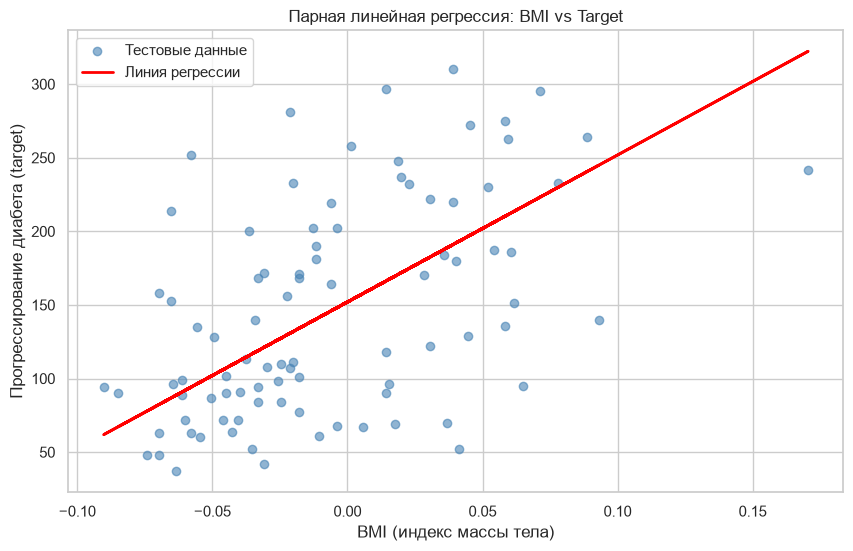

In [2]:
# X — один признак, y — целевая
X = df[['bmi']]
y = df['target']

# Разделение 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Обучение модели
model_simple = LinearRegression()
model_simple.fit(X_train, y_train)

# Параметры модели
slope = model_simple.coef_[0]
intercept = model_simple.intercept_

print("=== Парная линейная регрессия (bmi -> target) ===")
print(f"Коэффициент наклона (slope): {slope:.4f}")
print(f"Свободный член (intercept): {intercept:.4f}")
print(f"Формула: y = {slope:.2f} * x + {intercept:.2f}")

# Визуализация: точки + линия предсказания
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='steelblue', alpha=0.6, label='Тестовые данные')
plt.plot(X_test, model_simple.predict(X_test), color='red', linewidth=2, label='Линия регрессии')
plt.xlabel("BMI (индекс массы тела)")
plt.ylabel("Прогрессирование диабета (target)")
plt.title("Парная линейная регрессия: BMI vs Target")
plt.legend()
plt.show()

In [3]:
# Загрузка Advertising Dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"
try:
    df_adv = pd.read_csv(url)
    # Удаляем первый столбец с индексами, если он есть
    if 'Unnamed: 0' in df_adv.columns:
        df_adv = df_adv.drop(columns=['Unnamed: 0'])
except Exception as e:
    print(f"Ошибка загрузки URL: {e}")
    print("Используем альтернативный URL...")
    # Альтернативный источник
    url2 = "https://raw.githubusercontent.com/JWarmenhoven/ISLR-python/master/Notebooks/Data/Advertising.csv"
    df_adv = pd.read_csv(url2)

print("=== Датасет 2: Advertising (для множественной регрессии) ===")
print("Размер:", df_adv.shape)
print("\nПропуски:\n", df_adv.isnull().sum())
display(df_adv.head())

=== Датасет 2: Advertising (для множественной регрессии) ===
Размер: (200, 4)

Пропуски:
 TV           0
radio        0
newspaper    0
sales        0
dtype: int64


,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [6]:
# Загрузка Advertising Dataset
url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"
df_adv = pd.read_csv(url)

# Удаляем безымянный столбец, если он есть
if 'Unnamed: 0' in df_adv.columns:
    df_adv = df_adv.drop(columns=['Unnamed: 0'])

# Приводим названия колонок к стандартному виду (с большой буквы, без пробелов)
df_adv.columns = [col.strip().capitalize() for col in df_adv.columns]

print("=== Датасет 2: Advertising ===")
print("Размер:", df_adv.shape)
print("Колонки:", df_adv.columns.tolist())
print("\nПропуски:\n", df_adv.isnull().sum())
display(df_adv.head())

=== Датасет 2: Advertising ===
Размер: (200, 4)
Колонки: ['Tv', 'Radio', 'Newspaper', 'Sales']

Пропуски:
 Tv           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


,Tv,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [8]:
# Целевая переменная — Sales (или sales)
y_adv = df_adv['Sales']

# Эксперимент А: только TV (пишем Tv, как получилось после capitalize)
X_A = df_adv[['Tv']]
# Эксперимент Б: TV + Radio
X_B = df_adv[['Tv', 'Radio']]
# Эксперимент В: все признаки
X_C = df_adv[['Tv', 'Radio', 'Newspaper']]

results = []

for name, X in [("А: TV", X_A), ("Б: TV+Radio", X_B), ("В: TV+Radio+Newspaper", X_C)]:
    X_train, X_test, y_train, y_test = train_test_split(X, y_adv, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        "Эксперимент": name,
        "Признаки": ", ".join(X.columns),
        "MAE": round(mae, 3),
        "MSE": round(mse, 3),
        "R2": round(r2, 4)
    })
    print(f"{name}: MAE={mae:.3f}, MSE={mse:.3f}, R2={r2:.4f}")

А: TV: MAE=2.444, MSE=10.205, R2=0.6767
Б: TV+Radio: MAE=1.444, MSE=3.138, R2=0.9006
В: TV+Radio+Newspaper: MAE=1.461, MSE=3.174, R2=0.8994


=== Сравнительная таблица моделей ===


,Эксперимент,Признаки,MAE,MSE,R2
0,Парная (Diabetes),bmi,52.260,4061.826,0.2334
1,Парная (Diabetes),bmi,52.260,4061.826,0.2334
2,А: TV,Tv,2.444,10.205,0.6767
3,Б: TV+Radio,"Tv, Radio",1.444,3.138,0.9006
4,В: TV+Radio+Newspaper,"Tv, Radio, Newspaper",1.461,3.174,0.8994


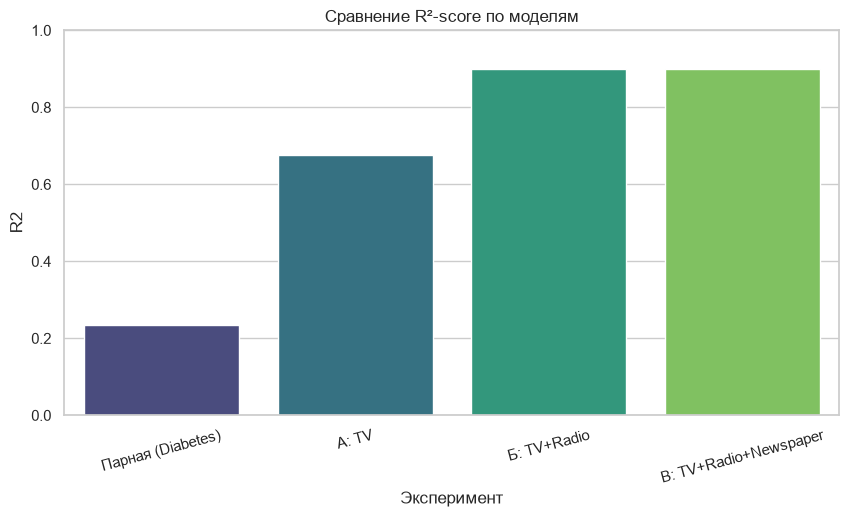

In [10]:
# Пересчитаем метрики для Diabetes, чтобы не путаться с переменными
X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(df[['bmi']], df['target'], test_size=0.2, random_state=42)
y_pred_d = model_simple.predict(X_te_d)

results.insert(0, {
    "Эксперимент": "Парная (Diabetes)",
    "Признаки": "bmi",
    "MAE": round(mean_absolute_error(y_te_d, y_pred_d), 3),
    "MSE": round(mean_squared_error(y_te_d, y_pred_d), 3),
    "R2": round(r2_score(y_te_d, y_pred_d), 4)
})

# Создаём DataFrame
df_results = pd.DataFrame(results)
print("=== Сравнительная таблица моделей ===")
display(df_results)

# Визуализация сравнения R2 (исправленный график без предупреждений)
plt.figure(figsize=(10, 5))
sns.barplot(data=df_results, x="Эксперимент", y="R2", hue="Эксперимент", palette="viridis", legend=False)
plt.title("Сравнение R²-score по моделям")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()